In [2]:
#ACTIVIDAD 2 Limpieza y análisis de datos con Pandas + NumPY Eliza yepes
import pandas as pd
import numpy as np



In [3]:
df = pd.read_csv("animal_data_dirty1.csv", sep=";")

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1011 entries, 0 to 1010
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Animal type       991 non-null    str    
 1   Country           999 non-null    str    
 2   Weight kg         984 non-null    float64
 3   Body Length cm    984 non-null    float64
 4   Gender            992 non-null    str    
 5   Animal code       0 non-null      float64
 6   Latitude          913 non-null    float64
 7   Longitude         913 non-null    float64
 8   Animal name       52 non-null     str    
 9   Observation date  1011 non-null   str    
 10  Data compiled by  1011 non-null   str    
dtypes: float64(5), str(6)
memory usage: 87.0 KB


In [5]:
df.isnull().sum()

Animal type           20
Country               12
Weight kg             27
Body Length cm        27
Gender                19
Animal code         1011
Latitude              98
Longitude             98
Animal name          959
Observation date       0
Data compiled by       0
dtype: int64

In [6]:
df[["Animal name"]].dropna()

,Animal name
2,Szefu
9,Basia
11,Lolek
51,Basia
53,Lolek
131,Lola
136,Lola
151,Lola
156,Lola
282,Basia


#Eliminare dos columnas inicialmente, Animal code porque todos sus valores son nulos y Animal name porque apenas con sus 52 datos de nombres individuales, no son tan relevantes para el analasis a comparacion por ejemplo de un Animal type 

In [7]:
df = df.drop(columns=["Animal code", "Animal name"])

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1011 entries, 0 to 1010
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Animal type       991 non-null    str    
 1   Country           999 non-null    str    
 2   Weight kg         984 non-null    float64
 3   Body Length cm    984 non-null    float64
 4   Gender            992 non-null    str    
 5   Latitude          913 non-null    float64
 6   Longitude         913 non-null    float64
 7   Observation date  1011 non-null   str    
 8   Data compiled by  1011 non-null   str    
dtypes: float64(4), str(5)
memory usage: 71.2 KB


In [9]:
df.isnull().sum()

Animal type         20
Country             12
Weight kg           27
Body Length cm      27
Gender              19
Latitude            98
Longitude           98
Observation date     0
Data compiled by     0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(167)

In [11]:
df[df.duplicated()]

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
51,red squirel,Poland,0.308,22.0,female,52.241273,21.055745,01.03.2024,Anne Anthony
52,red squirrel,PL,0.348,20.0,female,52.242060,21.057802,01.03.2024,Anne Anthony
53,red squirrel,Poland,0.316,20.0,male,52.240035,21.056188,01.03.2024,Anne Anthony
54,red squirrel,Poland,0.340,21.0,NaN,52.240284,21.051948,01.03.2024,Anne Anthony
55,red squirrel,Poland,0.333,21.0,male,NaN,NaN,01.03.2024,Anne Anthony
...,...,...,...,...,...,...,...,...,...
988,red squirrel,Poland,0.317,19.0,female,52.212310,21.033586,4 May 2024,Anne Anthony
1002,red squirrel,Poland,0.301,22.0,male,52.212760,21.034189,6 May 2024,Anne Anthony
1003,red squirrel,Poland,0.343,22.0,male,52.212497,21.033515,6 May 2024,Anne Anthony
1004,red squirrel,Poland,0.307,20.0,female,52.212144,21.033534,6 May 2024,Anne Anthony


In [12]:
df = df.drop_duplicates()

#Eliminamos los duplicados :D

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["Animal type"] = df["Animal type"].str.strip().str.lower()

In [15]:
df["Country"] = df["Country"].str.strip().str.lower()

In [16]:
df["Gender"] = df["Gender"].str.strip().str.lower()

In [17]:
df["Data compiled by"] = df["Data compiled by"].str.strip().str.title()

In [18]:
df["Animal type"].value_counts()

Animal type
red squirrel       387
hedgehog           274
lynx                61
european bison      49
red squirrell       16
lynx?               10
red squirel         10
european bison™      6
european bisson      4
european buster      4
ledgehod             3
wedgehod             1
Name: count, dtype: int64

In [19]:
df["Animal type"] = df["Animal type"].replace({
    "red squirrel1": "red squirrel",
    "red squirel": "red squirrel",
    "red squirrell": "red squirrel"
})

In [20]:
df["Animal type"] = df["Animal type"].replace({
    "lynx?": "lynx"
})

In [21]:
df["Animal type"] = df["Animal type"].replace({
    "european bison™": "european bison",
    "european bisson": "european bison"
})

In [22]:
df["Animal type"] = df["Animal type"].replace({
    "ledgehog": "hedgehog",
    "wedgehod": "hedgehog",
    "ledgehod": "hedgehog"
})

In [23]:
df[df["Animal type"] == "european buster"]

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
6,european buster,poland,620.0,250.0,female,52.834960,23.820750,01.03.2024,Anne Anthony
100,european buster,czech republic,572.0,251.0,female,50.638945,14.845452,02.03.2024,John Johnson
380,european buster,czech republic,360.0,175.0,female,50.636642,14.847946,21.03.2024,John Johnson
595,european buster,poland,589.0,279.0,female,52.808704,23.705504,06.04.2024,Anne Anthony


In [24]:
df[df["Animal type"] == "european bison"]

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
2,european bison,poland,930.0,335.0,male,52.828845,23.820144,01.03.2024,Anne Anthony
3,european bison,poland,909.0,311.0,not determined,52.830509,23.826849,01.03.2024,Anne Anthony
4,european bison,poland,581.0,277.0,female,52.834109,23.807093,01.03.2024,Anne Anthony
5,european bison,poland,900.0,295.0,male,52.834759,23.817201,01.03.2024,Anne Anthony
36,european bison,slovakia,420.0,182.0,male,49.054684,22.417189,01.03.2024,John Johnson
37,european bison,slovakia,511.0,266.0,female,49.053629,22.421831,01.03.2024,John Johnson
38,european bison,slovakia,814.0,288.0,male,49.053489,22.415229,01.03.2024,John Johnson
39,european bison,slovakia,130.0,141.0,female,49.054166,22.422852,01.03.2024,John Johnson
40,european bison,slovakia,390.0,180.0,female,49.052731,22.422675,01.03.2024,John Johnson
41,european bison,slovakia,355.0,179.0,male,49.055974,22.415985,01.03.2024,John Johnson


#A mi parecer  que buster es el misomo bisonte europeo  por que tienen varias variables iguales 

In [25]:
df["Animal type"] = df["Animal type"].replace({
    "european buster": "european bison"
})

In [26]:
df["Animal type"].value_counts()

Animal type
red squirrel      413
hedgehog          278
lynx               71
european bison     63
Name: count, dtype: int64

In [27]:
df["Country"].value_counts()

Country
poland            182
germany           173
slovakia          151
hungary           103
czech republic    103
austria            74
pl                 10
hu                  8
hungry              7
cz                  5
de                  5
czech               4
australia           4
cc                  4
Name: count, dtype: int64

In [28]:
df["Country"] = df["Country"].replace({
    "pl": "poland",
    "hu": "hungary",
    "cz": "czech republic",
    "de": "germany"
})

In [29]:
df["Country"].value_counts()

Country
poland            192
germany           178
slovakia          151
hungary           111
czech republic    108
austria            74
hungry              7
czech               4
australia           4
cc                  4
Name: count, dtype: int64

In [30]:
df["Country"] = df["Country"].replace({
    "hungry": "hungary"
})

In [31]:
df["Country"] = df["Country"].replace({
    "czech": "czech republic"
})

In [32]:
df["Country"].value_counts()

Country
poland            192
germany           178
slovakia          151
hungary           118
czech republic    112
austria            74
australia           4
cc                  4
Name: count, dtype: int64

In [33]:
df[df["Country"] == "australia"]

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
295,hedgehog,australia,0.800,24.0,not determined,47.781689,14.386777,14.03.2024,Bob Bobson
370,hedgehog,australia,0.600,14.0,female,47.781248,14.382649,21.03.2024,Bob Bobson
583,red squirrel,australia,0.266,20.0,female,47.781632,14.382365,05.04.2024,Bob Bobson
688,red squirrel,australia,0.310,23.0,male,47.856092,15.083547,11.04.2024,Bob Bobson


#*MMM INVESTIGANDO creo hay un error de escritura porque internet dice esto :*
Australia está en Oceanía, en la latitud -25.274398 y longitud 133.775136. 
Austria está en Europa, en la latitud 47.516231 y longitud 14.550072
segun nuestra tabla vemos que los datos corresponden a Austria y no a australia 




In [34]:
df["Country"] = df["Country"].replace({
    "australia": "austria"
})

In [35]:
df["Country"].value_counts()

Country
poland            192
germany           178
slovakia          151
hungary           118
czech republic    112
austria            78
cc                  4
Name: count, dtype: int64

In [36]:
df[df["Country"] == "cc"]

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
397,european bison,cc,603.0,291.0,male,50.644813,14.839817,22.03.2024,John Johnson
398,european bison,cc,717.0,305.0,male,50.635565,14.839320,22.03.2024,John Johnson
661,european bison,cc,560.0,250.0,female,50.645077,14.840304,08.04.2024,John Johnson
777,european bison,cc,656.0,245.0,female,50.643056,14.843037,19.04.2024,John Johnson


#Tambien busque estas cordenadas y da en republica checa 

In [37]:
df["Country"] = df["Country"].replace({
    "cc": "czech republic"
})

In [38]:
df["Country"].value_counts()

Country
poland            192
germany           178
slovakia          151
hungary           118
czech republic    116
austria            78
Name: count, dtype: int64

In [39]:
df["Gender"].value_counts()

Gender
male              423
female            401
not determined      5
Name: count, dtype: int64

In [40]:
df["Data compiled by"].value_counts()

Data compiled by
Anne Anthony     310
Bob Bobson       256
John Johnson     249
James Johnson     29
Name: count, dtype: int64

In [41]:
df["Data compiled by"].unique()

<StringArray>
['James Johnson', 'Anne Anthony', 'Bob Bobson', 'John Johnson']
Length: 4, dtype: str

In [42]:
df.isnull().sum()

Animal type         19
Country             11
Weight kg           20
Body Length cm      20
Gender              15
Latitude            92
Longitude           92
Observation date     0
Data compiled by     0
dtype: int64

In [43]:
df[["Weight kg", "Body Length cm", "Latitude", "Longitude"]].info()

<class 'pandas.DataFrame'>
Index: 844 entries, 0 to 1010
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Weight kg       824 non-null    float64
 1   Body Length cm  824 non-null    float64
 2   Latitude        752 non-null    float64
 3   Longitude       752 non-null    float64
dtypes: float64(4)
memory usage: 33.0 KB


In [44]:
df[["Weight kg", "Body Length cm", "Latitude", "Longitude"]].describe()

,Weight kg,Body Length cm,Latitude,Longitude
count,824.000000,824.000000,752.000000,752.000000
mean,47.405415,42.714806,49.261040,17.641278
std,169.747141,63.410847,7.360449,3.977238
min,-0.252000,-19.000000,-78.582973,11.074008
25%,0.298000,19.000000,48.186018,14.348492
50%,0.350000,21.000000,49.057679,18.849445
75%,1.000000,23.000000,52.211972,21.032016
max,1100.000000,350.000000,52.853843,34.896734


In [45]:
df[df["Body Length cm"] < 0]

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
47,hedgehog,czech republic,0.600,-16.0,male,50.644733,14.835753,01.03.2024,John Johnson
124,red squirrel,hungary,0.307,-19.0,male,NaN,NaN,04.03.2024,Anne Anthony
162,red squirrel,hungary,0.253,-19.0,male,47.507002,18.950091,05.03.2024,Anne Anthony
225,hedgehog,poland,0.600,-19.0,male,52.214410,21.032484,09.03.2024,Anne Anthony


In [46]:
df[df["Animal type"] == "red squirrel"]["Body Length cm"].describe()



count    407.000000
mean      20.329238
std        3.316581
min      -19.000000
25%       19.000000
50%       20.000000
75%       22.000000
max       24.000000
Name: Body Length cm, dtype: float64

In [47]:
df[df["Animal type"] == "hedgehog"]["Body Length cm"].describe()

count    275.000000
mean      19.952727
std        9.301987
min      -19.000000
25%       17.000000
50%       20.000000
75%       22.000000
max      151.000000
Name: Body Length cm, dtype: float64

#parece una equivocacion por el "-" 

In [48]:
df.loc[df["Body Length cm"] < 0, "Body Length cm"] = (
    df.loc[df["Body Length cm"] < 0, "Body Length cm"].abs()
)

In [49]:
df["Body Length cm"].min()

np.float64(11.0)

In [50]:
df[df["Weight kg"] < 0]

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
457,red squirrel,hungary,-0.251,20.0,female,47.508618,18.944915,26.03.2024,Anne Anthony
503,red squirrel,hungary,-0.250,19.0,female,47.509538,18.945968,31.03.2024,Anne Anthony
663,red squirrel,slovakia,-0.252,21.0,male,49.057599,22.422203,08.04.2024,John Johnson


In [51]:
df[df["Animal type"] == "red squirrel"]["Weight kg"].describe()

count    407.000000
mean       0.293523
std        0.054714
min       -0.252000
25%        0.275000
50%        0.298000
75%        0.320000
max        0.360000
Name: Weight kg, dtype: float64

In [52]:
df.loc[df["Weight kg"] < 0, "Weight kg"] = (
    df.loc[df["Weight kg"] < 0, "Weight kg"].abs()
)

In [53]:
df["Weight kg"].min()

np.float64(0.2)

In [54]:
df[df["Weight kg"] > 100]

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
2,european bison,poland,930.0,335.0,male,52.828845,23.820144,01.03.2024,Anne Anthony
3,european bison,poland,909.0,311.0,not determined,52.830509,23.826849,01.03.2024,Anne Anthony
4,european bison,poland,581.0,277.0,female,52.834109,23.807093,01.03.2024,Anne Anthony
5,european bison,poland,900.0,295.0,male,52.834759,23.817201,01.03.2024,Anne Anthony
6,european bison,poland,620.0,250.0,female,52.834960,23.820750,01.03.2024,Anne Anthony
36,european bison,slovakia,420.0,182.0,male,49.054684,22.417189,01.03.2024,John Johnson
37,european bison,slovakia,511.0,266.0,female,49.053629,22.421831,01.03.2024,John Johnson
38,european bison,slovakia,814.0,288.0,male,49.053489,22.415229,01.03.2024,John Johnson
39,european bison,slovakia,130.0,141.0,female,49.054166,22.422852,01.03.2024,John Johnson
40,european bison,slovakia,390.0,180.0,female,49.052731,22.422675,01.03.2024,John Johnson


In [55]:
df[df["Animal type"] == "lynx"]["Weight kg"].describe()

count     71.000000
mean      23.267606
std       18.401830
min       11.000000
25%       18.000000
50%       22.000000
75%       25.000000
max      171.000000
Name: Weight kg, dtype: float64

In [56]:
df[(df["Animal type"] == "lynx") & (df["Weight kg"] == 171)]

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
364,lynx,poland,171.0,75.0,male,52.831229,23.814123,21.03.2024,Anne Anthony


In [57]:
df[
    (df["Animal type"] == "lynx") &
    (df["Body Length cm"].between(70, 80))
][["Weight kg", "Body Length cm", "Country", "Gender"]]

,Weight kg,Body Length cm,Country,Gender
7,24.0,76.0,hungary,male
63,23.0,78.0,hungary,female
159,24.0,79.0,hungary,male
228,23.0,73.0,hungary,female
242,23.0,77.0,hungary,female
243,15.0,71.0,hungary,male
301,22.0,80.0,austria,female
307,16.0,70.0,poland,male
314,16.0,72.0,poland,male
358,17.0,80.0,slovakia,female


#Al comparar el peso de los linces con longitudes  entre 70 y 80 cm,tienen un  peso entre 15 y 24 k..alparecer hay un error en el 364 dice que pesa 171.0 pero parece debia ser 17.1

In [58]:
df.loc[df["Weight kg"] == 171, "Weight kg"] = 17.1

In [59]:
df[df["Animal type"] == "lynx"]["Weight kg"].max()

np.float64(30.0)

In [60]:
df[(df["Animal type"] == "lynx") & (df["Weight kg"] == 30)]

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
109,lynx,slovakia,30.0,120.0,male,48.409308,18.832606,02.03.2024,John Johnson
916,lynx,slovakia,30.0,115.0,male,48.408025,18.865229,31.05.2024,John Johnson


Pense que 30k podia ser mucho para un lince pero ambos son machos y de longitud de mas de 120.0 asi que creo que eran machos mas grandes de lo comun 


In [61]:
df["Weight kg"].describe()

count     824.000000
mean       47.220471
std       169.695136
min         0.200000
25%         0.298000
50%         0.350000
75%         1.000000
max      1100.000000
Name: Weight kg, dtype: float64

In [62]:
df["Body Length cm"].describe()

count    824.000000
mean      42.891990
std       63.290986
min       11.000000
25%       19.000000
50%       21.000000
75%       23.000000
max      350.000000
Name: Body Length cm, dtype: float64

In [63]:
df[df["Animal type"] == "european bison"]["Body Length cm"].describe()

count     63.000000
mean     244.238095
std       62.371084
min      100.000000
25%      211.000000
50%      255.000000
75%      289.500000
max      350.000000
Name: Body Length cm, dtype: float64

In [64]:
df[["Latitude", "Longitude"]].describe()

,Latitude,Longitude
count,752.000000,752.000000
mean,49.261040,17.641278
std,7.360449,3.977238
min,-78.582973,11.074008
25%,48.186018,14.348492
50%,49.057679,18.849445
75%,52.211972,21.032016
max,52.853843,34.896734


In [65]:
df[df["Latitude"] < 0]

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
202,red squirrel,hungary,0.296,19.0,male,-2.023546,34.896734,07.03.2024,Anne Anthony
253,red squirrel,hungary,0.282,21.0,male,-2.023546,34.896734,11.03.2024,Anne Anthony
780,lynx,czech republic,12.000,52.0,male,-78.582972,14.367993,19.04.2024,John Johnson
796,lynx,czech republic,23.000,78.0,male,-78.582973,14.366824,22.04.2024,John Johnson


#internet dice que estas coordenadas no existen -2.023546	34.896734 & -78.582972	14.367993	

In [66]:
df[
    (df["Animal type"] == "red squirrel") &
    (df["Country"] == "hungary")
][["Latitude", "Longitude"]].describe()

,Latitude,Longitude
count,48.000000,48.000000
mean,45.776938,20.142756
std,10.083489,3.199087
min,-2.023546,18.939808
25%,47.508237,18.943084
50%,47.510164,18.948093
75%,48.503040,20.543243
max,48.506429,34.896734


In [68]:
media_lat_hungary = df[
    (df["Animal type"] == "red squirrel") &
    (df["Country"] == "hungary") &
    (df["Latitude"] > 0)
]["Latitude"].mean()

media_lon_hungary = df[
    (df["Animal type"] == "red squirrel") &
    (df["Country"] == "hungary") &
    (df["Longitude"] > 0)
]["Longitude"].mean()

In [69]:
condicion = (
    (df["Animal type"] == "red squirrel") &
    (df["Country"] == "hungary") &
    (df["Latitude"] < 0)
)

df.loc[condicion, "Latitude"] = media_lat_hungary
df.loc[condicion, "Longitude"] = media_lon_hungary

In [70]:
df[df["Latitude"] < 0]

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
780,lynx,czech republic,12.0,52.0,male,-78.582972,14.367993,19.04.2024,John Johnson
796,lynx,czech republic,23.0,78.0,male,-78.582973,14.366824,22.04.2024,John Johnson


In [71]:
media_lat_czech = df[
    (df["Animal type"] == "lynx") &
    (df["Country"] == "czech republic") &
    (df["Latitude"] > 0)
]["Latitude"].mean()

media_lon_czech = df[
    (df["Animal type"] == "lynx") &
    (df["Country"] == "czech republic") &
    (df["Longitude"] > 0)
]["Longitude"].mean()

In [72]:
condicion = (
    (df["Animal type"] == "lynx") &
    (df["Country"] == "czech republic") &
    (df["Latitude"] < 0)
)

df.loc[condicion, "Latitude"] = media_lat_czech
df.loc[condicion, "Longitude"] = media_lon_czech

In [73]:
df[df["Latitude"] < 0]

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by


In [74]:
df.groupby("Country")[["Latitude", "Longitude"]].mean()

,Latitude,Longitude
Country,,
austria,47.713415,13.959314
czech republic,50.268944,14.409021
germany,49.894760,11.786535
hungary,48.000084,19.747704
poland,52.156686,21.908246
slovakia,48.444891,18.755130


In [79]:
df.sort_values("Longitude").tail(10)

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
630,NaN,austria,0.255,22.0,male,NaN,NaN,06.04.2024,Bob Bobson
631,NaN,austria,0.300,20.0,male,NaN,NaN,06.04.2024,Bob Bobson
632,NaN,austria,0.252,21.0,male,NaN,NaN,06.04.2024,Bob Bobson
833,NaN,NaN,NaN,NaN,NaN,NaN,NaN,03.05.2024,James Johnson
934,NaN,NaN,NaN,NaN,NaN,NaN,NaN,03.06.2024,James Johnson
956,NaN,NaN,NaN,NaN,NaN,NaN,NaN,03.07.2024,James Johnson
963,NaN,NaN,NaN,NaN,NaN,NaN,NaN,03.08.2024,James Johnson
968,NaN,NaN,NaN,NaN,NaN,NaN,NaN,03.13.2024,James Johnson
969,NaN,NaN,NaN,NaN,NaN,NaN,NaN,03.14.2024,James Johnson
970,NaN,NaN,NaN,NaN,NaN,NaN,NaN,03.22.2024,James Johnson


In [80]:
df.dropna(subset=["Longitude"]).sort_values("Longitude").tail(10)

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
201,lynx,poland,26.0,85.0,female,52.808579,23.843768,07.03.2024,Anne Anthony
307,lynx,poland,16.0,70.0,male,52.803129,23.844358,15.03.2024,Anne Anthony
64,lynx,poland,29.0,94.0,male,52.809851,23.858071,02.03.2024,Anne Anthony
230,lynx,poland,18.0,63.0,male,52.812647,23.863299,09.03.2024,Anne Anthony
808,lynx,poland,14.0,65.0,female,52.851841,23.891580,25.04.2024,Anne Anthony
816,lynx,poland,12.0,52.0,male,52.848214,23.891978,28.04.2024,Anne Anthony
979,lynx,poland,20.0,87.0,female,52.852069,23.900870,2 may 2024,Anne Anthony
978,lynx,poland,13.0,63.0,female,52.846379,23.904990,2 may 2024,Anne Anthony
991,lynx,poland,24.0,89.0,female,52.847483,23.906057,5 May 2024,Anne Anthony
817,lynx,poland,27.0,95.0,female,52.853843,23.919668,28.04.2024,Anne Anthony


In [81]:
df.isnull().sum()

Animal type         19
Country             11
Weight kg           20
Body Length cm      20
Gender              15
Latitude            92
Longitude           92
Observation date     0
Data compiled by     0
dtype: int64

In [82]:
df[df["Latitude"].isnull()][["Animal type", "Country", "Latitude", "Longitude"]]

,Animal type,Country,Latitude,Longitude
0,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN
13,red squirrel,poland,NaN,NaN
21,red squirrel,germany,NaN,NaN
22,red squirrel,germany,NaN,NaN
...,...,...,...,...
956,NaN,NaN,NaN,NaN
963,NaN,NaN,NaN,NaN
968,NaN,NaN,NaN,NaN
969,NaN,NaN,NaN,NaN


In [83]:
df[df["Latitude"].isnull() & df["Animal type"].notnull()]

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
13,red squirrel,poland,0.333,21.0,male,NaN,NaN,01.03.2024,Anne Anthony
21,red squirrel,germany,0.294,19.0,male,NaN,NaN,01.03.2024,Bob Bobson
22,red squirrel,germany,0.250,19.0,female,NaN,NaN,01.03.2024,Bob Bobson
23,red squirrel,germany,0.262,21.0,male,NaN,NaN,01.03.2024,Bob Bobson
24,red squirrel,germany,0.267,21.0,female,NaN,NaN,01.03.2024,Bob Bobson
...,...,...,...,...,...,...,...,...,...
620,red squirrel,germany,0.315,20.0,male,NaN,NaN,06.04.2024,Bob Bobson
621,red squirrel,germany,0.304,21.0,male,NaN,NaN,06.04.2024,Bob Bobson
622,red squirrel,germany,0.241,19.0,male,NaN,NaN,06.04.2024,Bob Bobson
623,red squirrel,germany,0.248,22.0,male,NaN,NaN,06.04.2024,Bob Bobson


In [84]:
df["Latitude"] = df["Latitude"].fillna(
    df.groupby(["Animal type", "Country"])["Latitude"].transform("mean")
)

df["Longitude"] = df["Longitude"].fillna(
    df.groupby(["Animal type", "Country"])["Longitude"].transform("mean")
)

In [86]:
df[df["Latitude"].isnull()][
    ["Animal type", "Country", "Weight kg", "Body Length cm", "Latitude", "Longitude"]
]

,Animal type,Country,Weight kg,Body Length cm,Latitude,Longitude
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
111,NaN,NaN,NaN,NaN,NaN,NaN
164,NaN,austria,0.263,22.0,NaN,NaN
563,NaN,NaN,NaN,NaN,NaN,NaN
626,NaN,austria,0.319,20.0,NaN,NaN
627,NaN,austria,0.292,19.0,NaN,NaN
628,NaN,austria,0.319,19.0,NaN,NaN
629,NaN,austria,0.298,20.0,NaN,NaN
630,NaN,austria,0.255,22.0,NaN,NaN


#Estos 19 registros no tiene informacion suficiente como para imputar o recuperarlos, los eliminare 

In [88]:
df = df.dropna(subset=["Latitude", "Longitude"])

In [89]:
df[["Latitude", "Longitude"]].isnull().sum()

Latitude     0
Longitude    0
dtype: int64

In [91]:
df.shape

(825, 9)

In [92]:
df.isnull().sum()

Animal type         0
Country             0
Weight kg           9
Body Length cm      9
Gender              4
Latitude            0
Longitude           0
Observation date    0
Data compiled by    0
dtype: int64

In [93]:
df[df["Weight kg"].isnull()][
    ["Animal type", "Country", "Weight kg", "Body Length cm", "Gender"]
]

,Animal type,Country,Weight kg,Body Length cm,Gender
15,red squirrel,poland,NaN,NaN,male
193,hedgehog,hungary,NaN,NaN,female
273,red squirrel,hungary,NaN,NaN,female
367,red squirrel,poland,NaN,NaN,male
521,red squirrel,poland,NaN,NaN,male
707,red squirrel,poland,NaN,NaN,male
861,hedgehog,hungary,NaN,NaN,male
898,red squirrel,poland,NaN,NaN,male
972,hedgehog,hungary,NaN,NaN,male


In [94]:
df["Weight kg"] = df["Weight kg"].fillna(
    df.groupby(["Animal type", "Country"])["Weight kg"].transform("mean")
)

df["Body Length cm"] = df["Body Length cm"].fillna(
    df.groupby(["Animal type", "Country"])["Body Length cm"].transform("mean")
)

In [95]:
df[["Weight kg", "Body Length cm"]].isnull().sum()

Weight kg         0
Body Length cm    0
dtype: int64

In [96]:
df.isnull().sum()

Animal type         0
Country             0
Weight kg           0
Body Length cm      0
Gender              4
Latitude            0
Longitude           0
Observation date    0
Data compiled by    0
dtype: int64

In [97]:
df[df["Gender"].isnull()][
    ["Animal type", "Country", "Weight kg", "Body Length cm", "Gender"]
]

,Animal type,Country,Weight kg,Body Length cm,Gender
12,red squirrel,poland,0.340,21.0,NaN
135,red squirrel,poland,0.291,21.0,NaN
260,red squirrel,poland,0.304,22.0,NaN
351,red squirrel,slovakia,0.330,18.0,NaN


In [98]:
df[
    (df["Animal type"] == "red squirrel") &
    (df["Country"] == "poland")
]["Gender"].value_counts()

Gender
female    58
male      53
Name: count, dtype: int64

In [99]:
df[
    (df["Animal type"] == "red squirrel") &
    (df["Country"] == "slovakia")
]["Gender"].value_counts()

Gender
male              33
female            25
not determined     1
Name: count, dtype: int64

In [100]:
df.loc[
    (df["Animal type"] == "red squirrel") &
    (df["Country"] == "poland") &
    (df["Gender"].isnull()),
    "Gender"
] = "female"

In [101]:
df.loc[
    (df["Animal type"] == "red squirrel") &
    (df["Country"] == "slovakia") &
    (df["Gender"].isnull()),
    "Gender"
] = "male"

In [103]:
df.isnull().sum()

Animal type         0
Country             0
Weight kg           0
Body Length cm      0
Gender              0
Latitude            0
Longitude           0
Observation date    0
Data compiled by    0
dtype: int64

In [104]:
df["Observation date"].unique()

<StringArray>
['01.03.2024', '02.03.2024', '03.03.2024', '04.03.2024', '05.03.2024',
 '06.03.2024', '07.03.2024', '08.03.2024', '09.03.2024', '10.03.2024',
 ...
 '03.09.2024', '03.11.2024', '1 May 2024', '2 may 2024', '3 May 2024',
 '4 May 2024', '5 May 2024', '6 May 2024', '7 May 2024', '8 May 2024']
Length: 108, dtype: str

In [106]:
pd.to_datetime(df["Observation date"], dayfirst=True, format="mixed")

2      2024-03-01
3      2024-03-01
4      2024-03-01
5      2024-03-01
6      2024-03-01
          ...    
1005   2024-05-07
1006   2024-05-07
1007   2024-05-07
1008   2024-05-07
1010   2024-05-08
Name: Observation date, Length: 825, dtype: datetime64[us]

In [107]:
df["Observation date"] = pd.to_datetime(
    df["Observation date"],
    dayfirst=True,
    format="mixed"
)

In [108]:
df["Observation date"] = pd.to_datetime(
    df["Observation date"],
    errors="coerce",
    dayfirst=True,
    format="mixed"
)

In [109]:
df["Observation date"].isnull().sum()

np.int64(0)

In [110]:
df.info()

<class 'pandas.DataFrame'>
Index: 825 entries, 2 to 1010
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Animal type       825 non-null    str           
 1   Country           825 non-null    str           
 2   Weight kg         825 non-null    float64       
 3   Body Length cm    825 non-null    float64       
 4   Gender            825 non-null    str           
 5   Latitude          825 non-null    float64       
 6   Longitude         825 non-null    float64       
 7   Observation date  825 non-null    datetime64[us]
 8   Data compiled by  825 non-null    str           
dtypes: datetime64[us](1), float64(4), str(4)
memory usage: 64.5 KB


In [ ]:
df.describe()

,Weight kg,Body Length cm,Latitude,Longitude,Observation date
count,825.000000,825.000000,825.000000,825.000000,825
mean,47.165730,42.868936,49.739209,17.116283,2024-04-03 10:28:21.818181
min,0.200000,11.000000,47.316383,11.074008,2024-03-01 00:00:00
25%,0.298000,19.000000,48.226708,14.179739,2024-03-11 00:00:00
50%,0.360000,21.000000,49.561569,17.089420,2024-03-30 00:00:00
75%,1.000000,23.000000,50.881878,20.562565,2024-04-16 00:00:00
max,1100.000000,350.000000,52.853843,23.919668,2024-11-03 00:00:00
std,169.599414,63.255914,1.770821,4.038762,NaN


In [112]:
df[df["Observation date"] > "2024-05-31"]

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
921,red squirrel,poland,0.325,20.0,male,52.823959,23.817073,2024-06-01,Anne Anthony
922,red squirrel,poland,0.276,22.0,male,52.825746,23.815204,2024-06-01,Anne Anthony
923,red squirrel,poland,0.298,24.0,female,52.823595,23.814758,2024-06-01,Anne Anthony
924,red squirrel,poland,0.322,23.0,male,52.825363,23.816829,2024-06-01,Anne Anthony
925,red squirrel,poland,0.344,22.0,female,52.821958,23.811375,2024-06-01,Anne Anthony
926,red squirrel,poland,0.323,22.0,female,52.823084,23.816106,2024-06-01,Anne Anthony
933,hedgehog,slovakia,0.600,15.0,male,48.238913,17.065508,2024-06-02,John Johnson
935,hedgehog,slovakia,0.700,14.0,female,48.237762,17.067101,2024-06-03,John Johnson
936,hedgehog,slovakia,0.700,17.0,female,48.238517,17.090268,2024-06-03,John Johnson
937,hedgehog,slovakia,0.700,24.0,male,48.232384,17.067453,2024-06-05,John Johnson


In [113]:
df["Gender"].value_counts()

Gender
male              418
female            402
not determined      5
Name: count, dtype: int64

#Quedan 5 no determinados, deberia convertirlos a la moda o dejarlo asi porque no determinadoos tambien es un valor valido ? 
yo lo dejare asi. 

In [116]:
df.sample(10)

,Animal type,Country,Weight kg,Body Length cm,Gender,Latitude,Longitude,Observation date,Data compiled by
662,hedgehog,slovakia,1.100,25.0,male,48.412590,18.873020,2024-04-08,John Johnson
805,hedgehog,slovakia,0.600,15.0,female,48.185648,17.083763,2024-04-24,John Johnson
936,hedgehog,slovakia,0.700,17.0,female,48.238517,17.090268,2024-06-03,John Johnson
834,red squirrel,poland,0.305,19.0,female,52.212746,21.033832,2024-05-09,Anne Anthony
842,hedgehog,slovakia,0.800,24.0,female,48.239628,17.087298,2024-05-11,John Johnson
697,red squirrel,czech republic,0.308,22.0,female,50.106721,14.346231,2024-04-11,John Johnson
32,red squirrel,germany,0.245,22.0,male,49.749164,11.880954,2024-03-01,Bob Bobson
447,hedgehog,poland,0.900,22.0,female,52.214494,21.033154,2024-03-25,Anne Anthony
20,red squirrel,poland,0.328,23.0,male,52.241920,21.056347,2024-03-01,Anne Anthony
878,lynx,slovakia,22.000,85.0,male,48.411436,18.864780,2024-05-19,John Johnson


In [117]:
df.shape

(825, 9)

In [118]:
df.isnull().sum()

Animal type         0
Country             0
Weight kg           0
Body Length cm      0
Gender              0
Latitude            0
Longitude           0
Observation date    0
Data compiled by    0
dtype: int64

In [129]:
df["Animal type"].value_counts()

Animal type
red squirrel      413
hedgehog          278
lynx               71
european bison     63
Name: count, dtype: int64

In [143]:
import numpy as np

In [147]:
df["Longitud mayor a 200 cm"] = np.where(
    df["Body Length cm"] > 200,
    "Sí",
    "No"
)

In [148]:
df["Longitud mayor a 200 cm"].value_counts()

Longitud mayor a 200 cm
No    777
Sí     48
Name: count, dtype: int64

In [149]:
np.std(df["Body Length cm"])

np.float64(63.21756513390096)

In [140]:
df.groupby("Animal type")["Weight kg"].mean().sort_values(ascending=False)

Animal type
european bison    588.396825
lynx               21.100000
hedgehog            0.797910
red squirrel        0.297358
Name: Weight kg, dtype: float64

In [141]:
df.groupby("Country")["Weight kg"].mean().sort_values(ascending=False)

Country
poland            129.194869
czech republic     74.496190
slovakia           32.449093
hungary             2.883226
austria             2.050529
germany             0.456090
Name: Weight kg, dtype: float64

In [142]:
df.groupby("Animal type")["Body Length cm"].mean().sort_values(ascending=False)

Animal type
european bison    244.238095
lynx               82.901408
red squirrel       20.527306
hedgehog           20.201778
Name: Body Length cm, dtype: float64

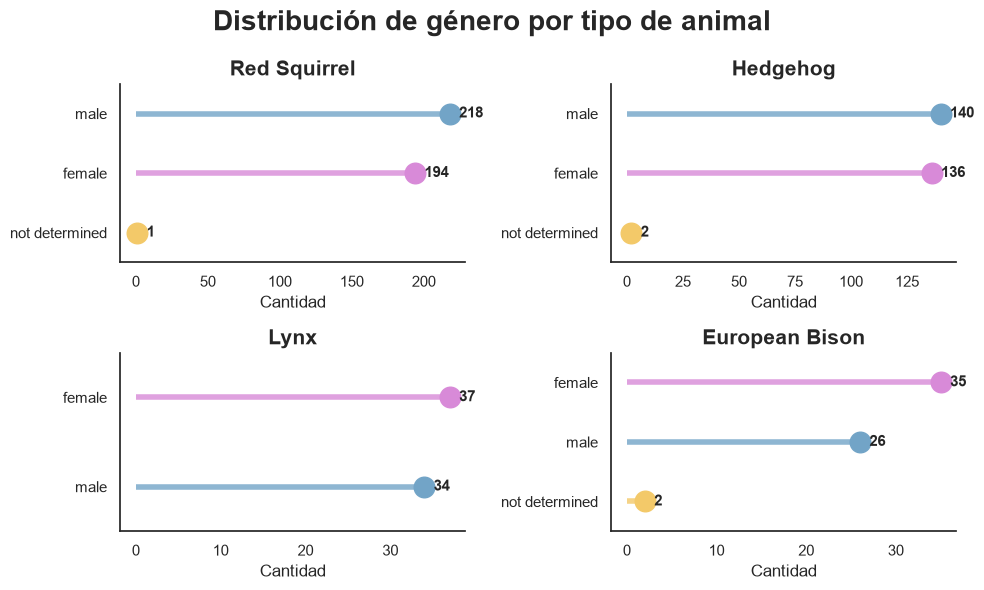

In [139]:
import seaborn as sns
import matplotlib.pyplot as plt

conteo = (
    df.groupby(["Animal type", "Gender"])
      .size()
      .reset_index(name="Cantidad")
)

animales = [
    "red squirrel",
    "hedgehog",
    "lynx",
    "european bison"
]

# Colores para cada género
colores = {
    "female": "#D88AD8",
    "male": "#72A4C7",
    "not determined": "#F3C969"
}

fig, axes = plt.subplots(2, 2, figsize=(10, 6))

for ax, animal in zip(axes.flat, animales):

    datos = conteo[
        conteo["Animal type"] == animal
    ].sort_values("Cantidad")

    # Lollipop
    for _, fila in datos.iterrows():

        genero = fila["Gender"]
        cantidad = fila["Cantidad"]

        # Línea
        ax.hlines(
            y=genero,
            xmin=0,
            xmax=cantidad,
            color=colores[genero],
            linewidth=4,
            alpha=0.8
        )

        # Punto
        ax.scatter(
            cantidad,
            genero,
            s=220,
            color=colores[genero],
            zorder=3
        )

        # Valor
        ax.text(
            cantidad + datos["Cantidad"].max() * 0.03,
            genero,
            f"{cantidad}",
            va="center",
            fontsize=11,
            fontweight="bold"
        )

    ax.set_title(
        animal.title(),
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel("Cantidad")
    ax.set_ylabel("")

    # Eliminar espacio vertical innecesario
    ax.set_ylim(-0.5, len(datos) - 0.5)

    sns.despine(ax=ax)

fig.suptitle(
    "Distribución de género por tipo de animal",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#Analisis de la base de datos 
#1 los problemas que encontre al analizar esta data fueron: casi 2 columnas enteras con datos nulos, paises mal escritos,diferentes nombres para cada grupo de animal, inconsistencias en  peso con valores negativos, inconsistencias en algunas cordenadas y algunos datos repetidos 
#2 El conjunto de datos contiene 413 individuos de red squirrel, 278 de hedgehog, 71 de lynx y 63 de european bison. Por lo tanto, la mayor parte de los registros corresponde a ardillas rojas y erizos, mientras que los linces y bisontes tienen una representación menor.
#3 El peso promedio varía considerablemente entre los países. Polonia presentó el mayor peso promedio, con aproximadamente 129,2 kg, mientras que Alemania presentó aproximadamente 0,46 kg. Esta diferencia está relacionada con los tipos de animales registrados en cada país, por lo que el promedio por país no representa necesariamente que los animales de un país sean más pesados que los de otro.
#4 La distribución por género fue bastante equilibrada en la base de datos. Se registraron 418  machos y 402 hembras, mientras que solo 5 observaciones tenían el género como “not determined”.